In [1]:
from pathlib import Path
import pandas as pd

print("Working directory:", Path.cwd())

Working directory: C:\dev\bank-marketing-ml-lab


In [2]:
data_path = Path("data/raw/bank-additional-full.csv")

if Path.cwd().name == "notebooks":
    data_path = Path("../data/raw/bank-additional-full.csv")

df = pd.read_csv(data_path, sep=";")

print(df.shape)
print(df.head())

(41188, 21)
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m 

In [3]:
print('rows: ', df.shape[0])
print('cols: ', df.shape[1])

print(df.dtypes)
df.info()

numerical_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

rows:  41188
cols:  21
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5  

In [4]:
print(numerical_cols)
print(categorical_cols)

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='str')
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='str')


In [5]:
target_dist = pd.DataFrame({'Count': df['y'].value_counts(),
                            '%': (df['y'].value_counts(normalize=True)*100).round(4)})
target_dist

,Count,%
y,,
no,36548,88.7346
yes,4640,11.2654


In [6]:
from IPython.display import display

# 1. Bang tong hop kiem tra gia tri thieu (NaN va unknown) tren toan bo 21 cot
missing_summary = pd.DataFrame({
    'Kiểu dữ liệu': df.dtypes,
    'Số lượng NaN': df.isna().sum(),
    'Tỷ lệ NaN (%)': (df.isna().mean() * 100).round(2),
    'Số lượng unknown': (df == 'unknown').sum(),
    'Tỷ lệ unknown (%)': ((df == 'unknown').mean() * 100).round(2)
})

# 2. Loc cac cot co xuat hien 'unknown' va sap xep giam dan theo so luong
unknown_cols = missing_summary[missing_summary['Số lượng unknown'] > 0].sort_values(
    by='Số lượng unknown', ascending=False
)

print('--- 1. Bảng tổng hợp kiểm tra dữ liệu thiếu (NaN & unknown) trên toàn bộ 21 thuộc tính ---')
display(missing_summary)

print('\n--- 2. Bảng lọc các thuộc tính có chứa giá trị unknown (dữ liệu thiếu thực tế) ---')
display(unknown_cols)

--- 1. Bảng tổng hợp kiểm tra dữ liệu thiếu (NaN & unknown) trên toàn bộ 21 thuộc tính ---


,Kiểu dữ liệu,Số lượng NaN,Tỷ lệ NaN (%),Số lượng unknown,Tỷ lệ unknown (%)
age,int64,0,0.0,0,0.00
job,str,0,0.0,330,0.80
marital,str,0,0.0,80,0.19
education,str,0,0.0,1731,4.20
default,str,0,0.0,8597,20.87
housing,str,0,0.0,990,2.40
loan,str,0,0.0,990,2.40
contact,str,0,0.0,0,0.00
month,str,0,0.0,0,0.00
day_of_week,str,0,0.0,0,0.00



--- 2. Bảng lọc các thuộc tính có chứa giá trị unknown (dữ liệu thiếu thực tế) ---


,Kiểu dữ liệu,Số lượng NaN,Tỷ lệ NaN (%),Số lượng unknown,Tỷ lệ unknown (%)
default,str,0,0.0,8597,20.87
education,str,0,0.0,1731,4.20
housing,str,0,0.0,990,2.40
loan,str,0,0.0,990,2.40
job,str,0,0.0,330,0.80
marital,str,0,0.0,80,0.19


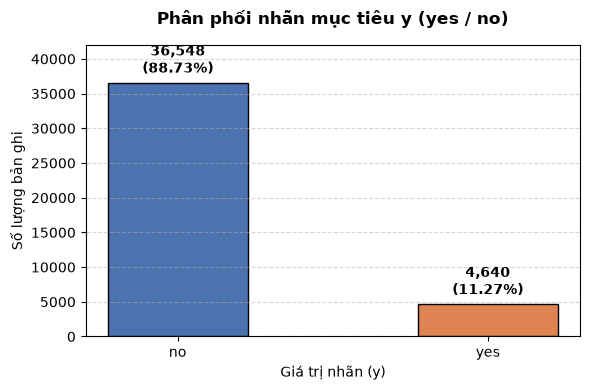

In [7]:
import matplotlib.pyplot as plt

# 1. Lấy dữ liệu phân phối
counts = df['y'].value_counts()
total = len(df)

# 2. Khởi tạo biểu đồ
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=['#4C72B0', '#DD8452'], edgecolor='black', width=0.45)

# 3. Ghi số lượng và phần trăm trên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    pct = (height / total) * 100
    ax.annotate(f'{height:,}\n({pct:.2f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# 4. Tinh chỉnh nhãn và tiêu đề
ax.set_title('Phân phối nhãn mục tiêu y (yes / no)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Giá trị nhãn (y)', fontsize=10)
ax.set_ylabel('Số lượng bản ghi', fontsize=10)
ax.set_ylim(0, max(counts.values) * 1.15)  # Tạo khoảng trống phía trên cho nhãn text
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()